# KI-Labor – Assignment 4: Transfer Learning (ausführliche Fassung mit Erklärungen)

> Diese Fassung enthält denselben Code und dieselben Ergebnisse wie die Abgabe, aber mit ausführlichen Kommentaren, Hintergrund zu jedem Schritt und am Ende einem Abschnitt mit möglichen Fragen und Antworten.

**Datensatz:** Food-101 (`torchvision.datasets.Food101`): Fotos von Gerichten, **101 Klassen** (z. B. `apple_pie`, `sushi`, `ramen`) mit je 1000 Bildern, davon 750 im offiziellen train- und 250 im test-Split. Die Fotos stammen von foodspotting.com (von Nutzern hochgeladen) und zeigen die Gerichte aus sehr unterschiedlichen Perspektiven, bei unterschiedlicher Beleuchtung und Anrichtung. Laut den Autoren (Bossard et al., ECCV 2014) enthalten die Trainingsbilder **absichtlich etwas Label-Rauschen**, die Testbilder wurden von Hand bereinigt.

*Warum Food-101?* Erlaubt laut Aufgabe (kein CIFAR/ImageNet/FashionMNIST/EMNIST), farbige Fotos in realistischer Größe, viele Klassen, balanciert. Mit 750 Bildern pro Klasse ist es groß genug, dass auch das Training von Grund auf eine Chance hat, und schwer genug, dass man Unterschiede zwischen den Ansätzen deutlich sieht.

**Vergleich:**

| Ansatz | Strategie |
|---|---|
| Custom CNN mit BatchNorm | von Grund auf trainiert (Baseline) |
| ResNet18 (ImageNet) | Fixed Feature Extractor / Fine-Tuning |
| EfficientNet_B5 (ImageNet) | Fixed Feature Extractor / Fine-Tuning |

**Für alle Ansätze gleich** (Aufgabe: „keep the experiment comparable“):
- **Split:** offizieller train-Split, davon 10 % als Validierung (Monitoring je Epoche); offizieller test-Split nur für die finale Bewertung, einmal pro Modell
- **Metrik:** Top-1-Accuracy auf dem Test-Split
- **Hardware:** dieselbe GPU (RTX 5060 Ti, 16 GB)
- **Trainingsschleife:** dieselbe Funktion `train()` mit bf16-Autocast
- **Zeitmessung:** gesamtes Training inkl. Validierung je Epoche, ohne Testen. Beim Feature Extractor zählt das Vorberechnen der Features dazu.

In [10]:
import random                     # Python-Zufallsgenerator (wird hier nur geseedet)
import time                       # Zeitmessung mit time.perf_counter()
from collections import Counter   # Dictionary, das Vorkommen zählt (Bildmodi, Klassenverteilung)

import matplotlib.pyplot as plt   # Plots: Beispielbilder, Lernkurven, Balkendiagramme
import numpy as np                # NumPy (wird hier nur geseedet, manche Bibliotheken nutzen es intern)
import pandas as pd               # Tabelle für den Vergleich aller Ansätze
import torch                      # PyTorch: Tensoren, GPU, Autograd
import torch.nn as nn             # Schichten (Conv2d, Linear, BatchNorm, ...) und Loss-Funktionen
import torch.nn.functional as F   # zustandslose Funktionen wie F.relu
import torch.optim as optim       # Optimierer (SGD, Adam)
import torchvision                # Datensätze, Modelle und Bildwerkzeuge für Computer Vision
import torchvision.transforms as transforms   # Vorverarbeitung der Bilder (Resize, ToTensor, Normalize, ...)
from PIL import Image             # Bilder öffnen, um Größe und Farbmodus zu untersuchen
from torch.utils.data import DataLoader, Subset, TensorDataset   # Batches laden, Teilmengen, Datensatz aus Tensoren
from torch.utils.tensorboard import SummaryWriter                # Lernkurven für TensorBoard schreiben
from torchvision.models import EfficientNet_B5_Weights, ResNet18_Weights, efficientnet_b5, resnet18   # vortrainierte Netze + Gewichte

# Fester Seed für alle Zufallsquellen -> gleiche Initialisierung, gleicher Split, gleiche Batch-Reihenfolge.
# (Bit-genau reproduzierbar ist das auf der GPU trotzdem nicht, z. B. wegen cudnn.benchmark.)
SEED = 42                # beliebige, aber feste Zahl
random.seed(SEED)        # Seed für Pythons random-Modul
np.random.seed(SEED)     # Seed für NumPy
torch.manual_seed(SEED)  # Seed für PyTorch (CPU und GPU)

# Gerät wählen: Apple-GPU (MPS), NVIDIA-GPU (CUDA) oder notfalls CPU
if torch.backends.mps.is_available():   # läuft auf einem Mac mit Apple-Silicon-GPU?
    DEVICE = torch.device("mps")  # Für Macs
elif torch.cuda.is_available():         # sonst: NVIDIA-GPU vorhanden?
    DEVICE = torch.device("cuda")       # dann rechnen wir auf der NVIDIA-GPU
else:                                   # weder MPS noch CUDA
    DEVICE = torch.device("cpu")        # Fallback: CPU (sehr langsam)
# Die Eingabegröße ist pro Modell immer gleich -> cuDNN probiert einmal mehrere Faltungs-Algorithmen
# aus und verwendet danach immer den schnellsten
torch.backends.cudnn.benchmark = True

print(f"PyTorch {torch.__version__} | Gerät: {DEVICE}")   # Version und gewähltes Gerät ausgeben

PyTorch 2.14.1+cu130 | Gerät: cuda


## 1. Datensatz laden und ansehen

**Split:** Food-101 hat nur einen train- und einen test-Split. Den test-Split während des Trainings anzuschauen (z. B. um die beste Epoche zu wählen) wäre eine versteckte Anpassung an die Testdaten. Deshalb werden 10 % des train-Splits zufällig, aber mit festem Seed, als Validierungsmenge abgetrennt. Alle Modelle bekommen exakt dieselben Indizes.

**Vorverarbeitung:**
- Custom CNN: Skalieren auf 64×64 px und Normalisieren auf [-1, 1]. Kleiner, damit das Netz schnell trainiert und `fc1` nicht explodiert.
- Vortrainierte Netze: `weights.transforms()`, also genau die Vorverarbeitung, mit der sie auf ImageNet trainiert wurden (Resize, Center-Crop, ImageNet-Mittelwert/-Std). Eine andere Vorverarbeitung würde die Eingabeverteilung verschieben, und die gelernten Features würden schlechter passen.
- **Augmentation:** nur zufälliges horizontales Spiegeln beim Training, denn ein gespiegeltes Gericht ist immer noch dasselbe Gericht.

In [11]:
# Food-101 einmalig herunterladen und entpacken (~5 GB, landet in ./data/food-101).
# Ist der Ordner schon vorhanden, passiert hier nichts. Alle späteren Aufrufe laden nur noch von der Platte.
DATA_ROOT = "./data"                # Ordner, in dem der Datensatz liegt
for split in ("train", "test"):     # beide offiziellen Splits einmal ansprechen
    torchvision.datasets.Food101(root=DATA_ROOT, split=split, download=True)   # lädt nur herunter, falls noch nicht da
print("Food-101 bereit")            # Bestätigung, dass die Daten vorhanden sind

Food-101 bereit


In [12]:
IMG_SIZE = 64        # Eingabegröße fürs Custom CNN
BATCH_SIZE = 32      # Bilder pro Batch (Standard für CNN und ResNet18)
NUM_WORKERS = 8      # parallele Prozesse, die JPEGs dekodieren und transformieren
VAL_FRACTION = 0.1   # Anteil des train-Splits, der als Validierung abgetrennt wird


def food101_splits(train_tf, eval_tf):
    """Offizieller train-Split -> 90 % Training / 10 % Validierung (immer dieselben Indizes), test bleibt test."""
    # Zwei Dataset-Objekte über denselben train-Split, damit Training (mit Augmentation)
    # und Validierung (ohne) unterschiedliche Transforms bekommen
    train_full = torchvision.datasets.Food101(root=DATA_ROOT, split="train", transform=train_tf)   # train-Split mit Trainings-Transform
    val_full = torchvision.datasets.Food101(root=DATA_ROOT, split="train", transform=eval_tf)     # derselbe train-Split, aber ohne Augmentation
    test = torchvision.datasets.Food101(root=DATA_ROOT, split="test", transform=eval_tf)         # offizieller test-Split, ohne Augmentation
    # Eigener Generator mit festem Seed -> bei jedem Aufruf (auch später für ResNet/EfficientNet)
    # exakt dieselbe Aufteilung, unabhängig vom globalen Zufallszustand
    perm = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(SEED)).tolist()
    n_val = int(VAL_FRACTION * len(perm))   # Anzahl Validierungsbilder (10 % von 75 750 = 7 575)
    # Subset = "Sicht" auf das Dataset mit ausgewählten Indizes, die Bilder werden nicht kopiert
    return Subset(train_full, perm[n_val:]), Subset(val_full, perm[:n_val]), test


def make_loader(dataset, batch_size=BATCH_SIZE, shuffle=False):
    # pin_memory: Batches liegen in "gepinntem" RAM -> schnellere Kopie auf die GPU
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=True)


# Vorverarbeitung fürs Custom CNN: feste Größe, Tensor in [0, 1], dann (x - 0.5) / 0.5 -> Werte in [-1, 1]
eval_transform = transforms.Compose([                        # mehrere Transforms nacheinander ausführen
    transforms.Resize((IMG_SIZE, IMG_SIZE)),                 # auf 64×64 px skalieren (Seitenverhältnis wird verzerrt)
    transforms.ToTensor(),                                   # PIL-Bild -> Tensor (Kanal, Höhe, Breite) mit Werten in [0, 1]
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # pro Kanal (x - 0.5) / 0.5 -> Werte in [-1, 1]
])                                                           # Ende der Transform-Liste
# Training zusätzlich mit zufälligem Spiegeln (Augmentation), Validierung/Test ohne
train_transform = transforms.Compose([transforms.RandomHorizontalFlip(), eval_transform])

trainset, valset, testset = food101_splits(train_transform, eval_transform)   # die drei Datensätze fürs CNN
trainloader = make_loader(trainset, shuffle=True)   # nur das Training wird gemischt
valloader = make_loader(valset)                     # Validierung in fester Reihenfolge
testloader = make_loader(testset)                   # Test in fester Reihenfolge

classes = testset.classes   # Klassennamen; das Subset selbst hat kein .classes
print(f"Train: {len(trainset)} | Val: {len(valset)} | Test: {len(testset)} Bilder")   # Größe der drei Splits

Train: 68175 | Val: 7575 | Test: 25250 Bilder


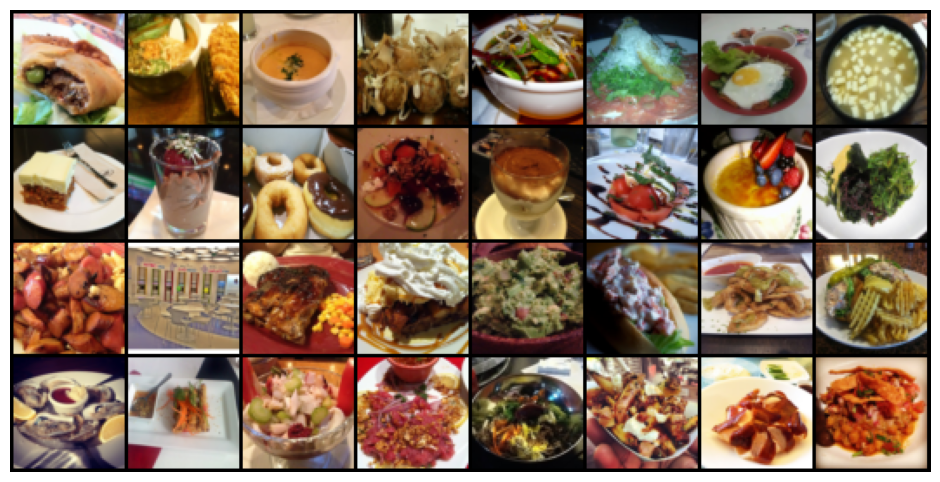

samosa, ramen, lobster_bisque, takoyaki, pho, beef_carpaccio, bibimbap, miso_soup, carrot_cake, chocolate_mousse, donuts, beet_salad, tiramisu, caprese_salad, creme_brulee, seaweed_salad, poutine, frozen_yogurt, baby_back_ribs, bread_pudding, guacamole, lobster_roll_sandwich, fried_calamari, lobster_roll_sandwich, oysters, spring_rolls, ceviche, beef_carpaccio, bibimbap, poutine, peking_duck, samosa


In [13]:
# Ein zufälliger Trainings-Batch als Beispielbilder (64×64, deshalb etwas grob)
images, labels = next(iter(trainloader))   # ersten Batch aus dem (gemischten) Trainings-Loader holen
plt.figure(figsize=(12, 6))                # neue Abbildung, 12×6 Zoll
# make_grid setzt die 32 Bilder zu einem Gitter zusammen; / 2 + 0.5 macht die Normalisierung rückgängig,
# permute bringt die Achsen von (Kanal, Höhe, Breite) in die Reihenfolge (Höhe, Breite, Kanal) für matplotlib
plt.imshow(torchvision.utils.make_grid(images / 2 + 0.5).permute(1, 2, 0))   # Normalisierung rückgängig
plt.axis("off")                            # keine Achsenbeschriftung
plt.show()                                 # Abbildung anzeigen
print(", ".join(classes[label] for label in labels))   # Klassennamen der 32 Bilder ausgeben

In [14]:
# Rohdaten ohne Transform, um die Originalbilder zu untersuchen
raw_train = torchvision.datasets.Food101(root=DATA_ROOT, split="train")   # train-Split ohne Vorverarbeitung
num_classes = len(raw_train.classes)                                       # Anzahl Klassen (101)

# Größe und Farbmodus jedes Bildes (RGB, L = Graustufen, ...)
sizes, modes = [], Counter()          # Liste der Bildgrößen, Zähler für Farbmodi
for file in raw_train._image_files:   # Image.open liest nur den Header, das geht schnell
    with Image.open(file) as img:     # Bild öffnen (wird am Ende des Blocks wieder geschlossen)
        sizes.append(img.size)        # (Breite, Höhe) merken
        modes[img.mode] += 1          # Farbmodus zählen
widths, heights = zip(*sizes)         # Liste von (B, H)-Paaren in zwei Tupel aufteilen
# 3 Kanäle: die wenigen Graustufenbilder wandelt torchvision beim Laden per .convert("RGB") um
in_channels = 3

# Klassenverteilung im eigenen Trainingsteil (nach Abtrennen der Validierung) -> entscheidet über die Metrik
counts = Counter(raw_train._labels[i] for i in trainset.indices)   # Klassenverteilung im Trainingsteil

print(f"Klassen: {num_classes}  (z.B. {raw_train.classes[:3]})")   # Anzahl Klassen und drei Beispiele
print(f"Modi: {dict(modes)}")                                       # wie viele Bilder pro Farbmodus
print(f"Breite: {min(widths)}–{max(widths)} px, Höhe: {min(heights)}–{max(heights)} px, "   # Spannweite der Bildgrößen
      f"{len(set(sizes))} verschiedene Größen")                     # Anzahl unterschiedlicher Größen
print(f"Trainingsbilder pro Klasse: {min(counts.values())}–{max(counts.values())}")   # kleinste/größte Klasse
# Form nach dem Transform, also das, was das CNN tatsächlich bekommt
print(f"Tensor-Shape fürs Custom CNN: {tuple(trainset[0][0].shape)}")

Klassen: 101  (z.B. ['apple_pie', 'baby_back_ribs', 'baklava'])
Modi: {'RGB': 75747, 'L': 3}
Breite: 193–512 px, Höhe: 122–512 px, 448 verschiedene Größen
Trainingsbilder pro Klasse: 651–689
Tensor-Shape fürs Custom CNN: (3, 64, 64)


**Ergebnis der Analyse:**

- **Größe:** 68 175 Trainings-, 7 575 Validierungs- und 25 250 Testbilder (offizieller Split: 75 750 train / 25 250 test)
- **Klassen:** 101 Gerichte
- **Input-Kanäle:** 3. Von 75 750 Trainingsbildern sind 75 747 RGB und 3 Graustufen (`L`). Der Bild-Loader von torchvision (`pil_loader`) ruft `.convert("RGB")` auf, das Netz bekommt also immer 3 Kanäle.
- **Bildgrößen:** sehr unterschiedlich (193–512 × 122–512 px, 448 verschiedene Größen). Die längere Seite ist praktisch immer 512 px, weil die Autoren die Bilder darauf verkleinert haben. Daher wird pro Modell auf eine feste Größe gebracht: CNN 64 px, ResNet18 224 px, EfficientNet_B5 456 px.
- **Metrik:** Die Klassen sind praktisch **balanciert** (651–689 Trainingsbilder pro Klasse nach dem Abtrennen der Validierung, im Test genau 250 pro Klasse). Deshalb ist die **Top-1-Accuracy** aussagekräftig, man braucht keine Balanced Accuracy oder Macro-F1. Zufallsniveau: 1/101 ≈ 1 %.

## 2. Custom CNN von Grund auf (Baseline)

Aufbau wie in Woche 3, aber mit `BatchNorm2d` nach jeder Faltung (Aufgabe: „include batch-normalisation layers in the convolutional part“):

```
Eingabe 3×64×64
→ Conv(3→32)   → BN → ReLU                    32×64×64
→ Conv(32→64)  → BN → ReLU → MaxPool          64×32×32
→ Conv(64→128) → BN → ReLU                   128×32×32
→ Conv(128→128)→ BN → ReLU → MaxPool         128×16×16
→ Flatten (32 768) → FC 512 → ReLU → Dropout 0.5 → FC 101
```

- **BatchNorm:** normalisiert jeden Kanal mit Mittelwert/Varianz des aktuellen Mini-Batches und lernt danach Skalierung γ und Verschiebung β. Das stabilisiert das Training. Im `eval()`-Modus werden stattdessen die während des Trainings gesammelten Running-Statistiken verwendet.
- `bias=False` bei den Faltungen: Ein Bias direkt vor BatchNorm wäre überflüssig, weil BN den Mittelwert ohnehin abzieht und mit β selbst eine Verschiebung lernt.
- **Optimierer:** SGD mit lr 0.01, Momentum 0.9, Weight Decay 5e-4 (L2-Regularisierung), 10 Epochen.
- Fast alle Parameter (16,8 von 17,1 M) stecken in `fc1` (32 768 × 512).

In [15]:
class BNNet(nn.Module):                                   # eigenes Netz, erbt von nn.Module
    def __init__(self, in_channels, num_classes, img_size):   # legt alle Schichten an
        super().__init__()                                # Konstruktor von nn.Module aufrufen (Pflicht)
        # 3×3-Faltungen mit padding=1 -> Höhe/Breite bleiben gleich, nur die Kanalzahl ändert sich.
        # bias=False, weil die folgende BatchNorm den Mittelwert abzieht und mit β selbst verschiebt.
        self.conv1 = nn.Conv2d(in_channels, 32, 3, padding=1, bias=False)   # 3 -> 32 Kanäle
        self.bn1 = nn.BatchNorm2d(32)                                        # BatchNorm über 32 Kanäle
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1, bias=False)            # 32 -> 64 Kanäle
        self.bn2 = nn.BatchNorm2d(64)                                        # BatchNorm über 64 Kanäle
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1, bias=False)           # 64 -> 128 Kanäle
        self.bn3 = nn.BatchNorm2d(128)                                       # BatchNorm über 128 Kanäle
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1, bias=False)          # 128 -> 128 Kanäle
        self.bn4 = nn.BatchNorm2d(128)                                       # BatchNorm über 128 Kanäle
        self.pool = nn.MaxPool2d(2, 2)    # halbiert Höhe und Breite
        self.dropout = nn.Dropout(0.5)    # schaltet im Training zufällig die Hälfte der Neuronen ab
        # Nach 2× Pooling: 128 Kanäle × (64/4)² = 128 × 16 × 16 = 32 768 Eingänge -> 16,8 M Gewichte
        self.fc1 = nn.Linear(128 * (img_size // 4) ** 2, 512)
        self.fc2 = nn.Linear(512, num_classes)   # Ausgabeschicht: ein Logit pro Klasse

    def forward(self, x):                                  # x: (B, 3, 64, 64)
        x = F.relu(self.bn1(self.conv1(x)))                # (B, 32, 64, 64)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))     # (B, 64, 32, 32)
        x = F.relu(self.bn3(self.conv3(x)))                # (B, 128, 32, 32)
        x = self.pool(F.relu(self.bn4(self.conv4(x))))     # (B, 128, 16, 16)
        x = torch.flatten(x, 1)                            # (B, 32768)
        x = self.dropout(F.relu(self.fc1(x)))              # (B, 512)
        return self.fc2(x)                                 # (B, 101) Logits, Softmax steckt im CrossEntropyLoss

In [16]:
# bf16-Autocast für alle Modelle gleich (sonst passt EfficientNet_B5 bei 456 px nicht in den GPU-Speicher)
USE_AMP = DEVICE.type == "cuda"     # Mixed Precision nur auf der NVIDIA-GPU einschalten
criterion = nn.CrossEntropyLoss()   # Softmax + negative Log-Likelihood, Standard für Klassifikation
results = []   # eine Zeile pro Ansatz für die Vergleichstabelle


def autocast():
    # Rechnet Faltungen/Matrixmultiplikationen automatisch in bfloat16: halber Speicher, schneller auf Tensor-Cores.
    # bfloat16 hat denselben Exponentenbereich wie float32 -> kein GradScaler nötig (anders als bei float16).
    return torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_AMP)


def count_trainable(net):
    # nur Parameter, die der Optimierer tatsächlich verändert (requires_grad=True)
    return sum(p.numel() for p in net.parameters() if p.requires_grad)


def evaluate(net, loader):
    """Durchschnittlicher Loss und Accuracy auf einem Datensatz, ohne Gradienten."""
    net.eval()   # BatchNorm nutzt dann die gelernten Statistiken, Dropout ist aus
    loss_sum = correct = total = 0      # Summen über alle Batches
    with torch.no_grad(), autocast():   # keine Gradienten -> weniger Speicher, schneller
        for inputs, labels in loader:   # Batch für Batch durch den Datensatz
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)   # Batch auf die GPU kopieren
            outputs = net(inputs).float()   # Logits zurück nach float32 für einen genauen Loss
            loss_sum += criterion(outputs, labels).item() * labels.size(0)   # criterion mittelt pro Batch -> mal Batchgröße
            correct += (outputs.argmax(1) == labels).sum().item()            # Top-1: Klasse mit dem höchsten Logit
            total += labels.size(0)     # Anzahl bisher ausgewerteter Bilder
    return loss_sum / total, correct / total   # mittlerer Loss und Accuracy


def train(net, optimizer, train_loader, val_loader, epochs, run_name):
    """Gemeinsame Trainingsschleife für alle Ansätze. Loggt nach runs/food101/<run_name> (TensorBoard)
    und gibt die Lernkurven und die Trainingszeit zurück."""
    net.to(DEVICE)                                         # Modell auf die GPU verschieben
    writer = SummaryWriter(f"runs/food101/{run_name}")     # eigener TensorBoard-Ordner pro Lauf
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}   # Werte pro Epoche
    start = time.perf_counter()   # Zeitmessung: alle Epochen inkl. Validierung, ohne Testen
    for epoch in range(epochs):   # eine Epoche = einmal durch alle Trainingsbilder
        net.train()   # BatchNorm mit Batch-Statistiken, Dropout aktiv
        loss_sum = correct = total = 0                     # Summen für diese Epoche zurücksetzen
        for inputs, labels in train_loader:                # Batch für Batch
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)   # Batch auf die GPU kopieren
            optimizer.zero_grad()            # Gradienten des letzten Schritts löschen (sonst addieren sie sich)
            with autocast():                 # Forward-Pass in bfloat16
                outputs = net(inputs).float()                # Vorhersage (Logits), zurück nach float32
                loss = criterion(outputs, labels)            # Loss für diesen Batch
            loss.backward()                  # Backpropagation: Gradienten für alle Parameter mit requires_grad
            optimizer.step()                 # Gewichte anhand der Gradienten anpassen
            # Train-Werte werden während der Epoche mitgezählt (Modell ändert sich dabei noch, Dropout aktiv)
            loss_sum += loss.item() * labels.size(0)                # Batch-Loss gewichtet aufsummieren
            correct += (outputs.argmax(1) == labels).sum().item()   # richtig klassifizierte Bilder zählen
            total += labels.size(0)                                 # Anzahl gesehener Bilder
        val_loss, val_acc = evaluate(net, val_loader)   # nach jeder Epoche auf der Validierung messen
        for key, value in zip(history, (loss_sum / total, correct / total, val_loss, val_acc)):   # die vier Werte den Schlüsseln zuordnen
            history[key].append(value)             # für die Lernkurven merken
            writer.add_scalar(key, value, epoch)   # Lernkurven für TensorBoard
        print(f"[{epoch + 1:2d}] train loss {loss_sum / total:.3f} acc {100 * correct / total:5.1f} % | "   # Fortschritt ausgeben
              f"val loss {val_loss:.3f} acc {100 * val_acc:5.1f} %")
    if DEVICE.type == "cuda":                      # nur auf NVIDIA-GPUs nötig
        torch.cuda.synchronize()   # GPU arbeitet asynchron -> warten, bis wirklich alles fertig ist, dann Zeit stoppen
    duration = time.perf_counter() - start         # gesamte Trainingszeit in Sekunden
    writer.close()                                 # TensorBoard-Datei schließen
    return history, duration                       # Lernkurven und Zeit zurückgeben


def report(model, strategy, resolution, epochs, trainable, train_time, test_acc, history):
    """Ergebnis ausgeben, in die Vergleichstabelle eintragen und Lernkurven plotten."""
    print(f"Test-Accuracy: {100 * test_acc:.2f} %  |  Trainingszeit: {train_time:.1f} s")   # Kurzfassung des Ergebnisses
    results.append({"Modell": model, "Strategie": strategy, "Auflösung": f"{resolution} px", "Epochen": epochs,   # neue Zeile für die Tabelle
                    "Trainierbare Parameter": trainable, "Trainingszeit [s]": round(train_time, 1),
                    "Test-Accuracy [%]": round(100 * test_acc, 2)})

    # links Loss, rechts Accuracy, jeweils Train- und Val-Kurve
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))   # zwei Diagramme nebeneinander
    epoch_axis = range(1, epochs + 1)                       # x-Achse: Epoche 1 bis N
    for ax, metric in ((ax1, "loss"), (ax2, "acc")):        # gleicher Code für beide Diagramme
        ax.plot(epoch_axis, history[f"train_{metric}"], marker="o", label="train")   # Trainingskurve
        ax.plot(epoch_axis, history[f"val_{metric}"], marker="o", label="val")       # Validierungskurve
        ax.set(title=f"{model} ({strategy}) – {'Loss' if metric == 'loss' else 'Accuracy'}", xlabel="Epoche")   # Titel und Achsenbeschriftung
        ax.legend()                                         # Legende train/val
    plt.show()                                              # Abbildung anzeigen

[ 1] train loss 4.619 acc   1.0 % | val loss 4.617 acc   0.9 %
[ 2] train loss 4.616 acc   0.9 % | val loss 4.616 acc   1.0 %
[ 3] train loss 4.616 acc   0.9 % | val loss 4.617 acc   0.8 %
[ 4] train loss 4.616 acc   0.9 % | val loss 4.617 acc   1.0 %
[ 5] train loss 4.609 acc   1.1 % | val loss 4.573 acc   2.1 %
[ 6] train loss 4.563 acc   1.8 % | val loss 4.470 acc   3.2 %
[ 7] train loss 4.451 acc   3.3 % | val loss 4.309 acc   5.7 %
[ 8] train loss 4.338 acc   4.2 % | val loss 4.190 acc   6.6 %
[ 9] train loss 4.211 acc   5.7 % | val loss 3.980 acc   9.7 %
[10] train loss 4.065 acc   7.5 % | val loss 3.884 acc  10.8 %
Test-Accuracy: 12.02 %  |  Trainingszeit: 555.2 s


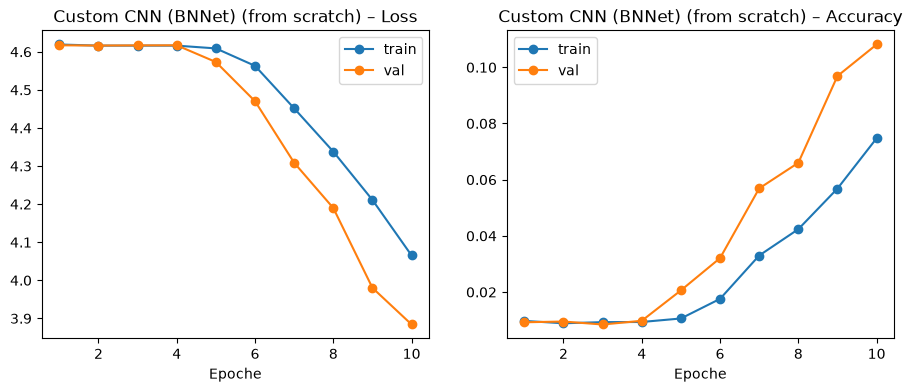

In [17]:
torch.manual_seed(SEED)   # gleiche Startgewichte bei jedem Lauf
EPOCHS_CNN = 10           # Anzahl Trainingsepochen fürs CNN
net = BNNet(in_channels, num_classes, IMG_SIZE)   # Netz mit zufälligen Startgewichten erzeugen
# SGD mit Momentum (glättet die Update-Richtung) und Weight Decay (L2-Regularisierung gegen Overfitting)
optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)

history, train_time = train(net, optimizer, trainloader, valloader, EPOCHS_CNN, "bnnet")   # trainieren
_, test_acc = evaluate(net, testloader)   # Test-Split: genau einmal, nach dem Training
report("Custom CNN (BNNet)", "from scratch", IMG_SIZE, EPOCHS_CNN, count_trainable(net), train_time, test_acc, history)   # Ergebnis eintragen + plotten
del net, optimizer   # GPU-Speicher für die nächsten Modelle freigeben

## 3. Transfer Learning: ResNet18 und EfficientNet_B5

**Idee:** Ein Netz, das auf ImageNet (1,2 M Bilder, 1000 Klassen) trainiert wurde, hat schon allgemein nützliche Merkmale gelernt: Kanten, Texturen, Formen und Objektteile. Diese werden für Food-101 wiederverwendet, ersetzt wird nur der letzte Klassifikationskopf (1000 → 101 Ausgänge).

Im Code wird jedes Netz in **Backbone** (alles bis inkl. globalem Average-Pooling, Ausgabe: Feature-Vektor) und **Kopf** aufgeteilt:

| Netz | Feature-Dimension | Kopf | ImageNet-Top-1 | Eingabe |
|---|---:|---|---:|---:|
| ResNet18 | 512 | `Linear(512, 101)` | ca. 69,8 % | 224 px |
| EfficientNet_B5 | 2048 | `Dropout(0.4)` + `Linear(2048, 101)` | ca. 83,4 % | 456 px |

**Fixed Feature Extractor:**
- Backbone eingefroren (`requires_grad=False`), trainiert wird nur der neue Kopf (Adam, lr 1e-3, 10 Epochen).
- Ein eingefrorenes Backbone liefert für jedes Bild immer denselben Feature-Vektor (im `eval`-Modus, ohne Augmentation). Deshalb werden die Features **einmal** für alle Bilder berechnet und gespeichert, danach wird nur der Kopf auf diesen Vektoren trainiert. Mathematisch ist das dasselbe Modell, nur viel schneller als jedes Bild in jeder Epoche neu durch das Backbone zu schicken. Einziger Unterschied: Weil jedes Bild nur einmal durchläuft, gibt es hier keine Spiegel-Augmentation.
- Das Backbone läuft im `eval`-Modus. So nutzt BatchNorm die ImageNet-Statistiken und verändert sie nicht.
- Die Trainingszeit umfasst Feature-Berechnung für train + val **und** Training des Kopfes. Das Testen wird wie bei allen anderen Ansätzen nicht mitgezählt.

**Fine-Tuning:**
- Alle Gewichte sind trainierbar, mit **differenzierten Lernraten** (Aufgabe: „adapt the learning rate appropriately“):
  - Backbone **1e-4**: Die vortrainierten Gewichte sind schon gut und sollen nur leicht angepasst werden. Eine große Lernrate würde sie am Anfang „zerstören“, solange der Kopf noch zufällige, große Gradienten liefert.
  - Kopf **1e-3**: startet zufällig und muss schnell lernen.
- Adam, 2 Epochen. Bei 68 175 Bildern und Batchgröße 32 sind das schon ca. 4 260 Update-Schritte (bei EfficientNet_B5 mit Batchgröße 16 doppelt so viele). Eine Epoche EfficientNet_B5 dauert ca. 28 min, mehr Epochen waren zeitlich nicht sinnvoll.

**Batchgröße:** EfficientNet_B5 bei 456 px braucht beim Fine-Tuning sehr viel GPU-Speicher (die Aktivierungen für den Backward-Pass), daher 16 statt 32.

In [18]:
# Konstruktor + ImageNet-Gewichte pro Architektur; DEFAULT = die besten verfügbaren Gewichte in torchvision
ARCHS = {
    "ResNet18": (resnet18, ResNet18_Weights.DEFAULT),                     # 11,7 M Parameter, 224 px
    "EfficientNet_B5": (efficientnet_b5, EfficientNet_B5_Weights.DEFAULT),  # 30,4 M Parameter, 456 px
}


def load_pretrained(arch):
    """Lädt das ImageNet-Modell und gibt (Backbone, neuer Kopf mit num_classes Ausgängen) zurück."""
    constructor, weights = ARCHS[arch]   # passende Funktion und Gewichte nachschlagen
    torch.manual_seed(SEED)   # gleiche Initialisierung des neuen Kopfes bei frozen und finetune
    net = constructor(weights=weights)   # Netz bauen und ImageNet-Gewichte laden
    if arch == "ResNet18":   # die beiden Netze heißen ihren Kopf unterschiedlich (fc vs. classifier)
        # ResNet18: ... -> avgpool -> flatten -> fc (512 -> 1000)
        head = nn.Linear(net.fc.in_features, num_classes)   # neuer Kopf 512 -> 101
        net.fc = nn.Identity()   # alter Kopf raus -> das Netz gibt jetzt den 512-dim. Feature-Vektor aus
    else:                    # EfficientNet_B5
        # EfficientNet: ... -> avgpool -> flatten -> classifier = [Dropout(0.4), Linear(2048 -> 1000)]
        net.classifier[1] = nn.Linear(net.classifier[1].in_features, num_classes)   # Linear-Schicht ersetzen: 2048 -> 101
        head = net.classifier   # Dropout + Linear
        net.classifier = nn.Identity()   # Backbone gibt den 2048-dim. Feature-Vektor aus
    return net.to(DEVICE), head.to(DEVICE)   # beide Teile auf die GPU


def extract_features(backbone, dataset, batch_size):
    """Schickt alle Bilder einmal durch das (eingefrorene) Backbone und speichert die Feature-Vektoren."""
    backbone.eval()   # BatchNorm behält die ImageNet-Statistiken
    features, labels = [], []            # hier werden die Ergebnisse Batch für Batch gesammelt
    with torch.no_grad(), autocast():    # keine Gradienten nötig, Backbone wird nicht trainiert
        for inputs, targets in make_loader(dataset, batch_size):   # alle Bilder in fester Reihenfolge
            features.append(backbone(inputs.to(DEVICE)).float().cpu())   # im RAM sammeln, nicht auf der GPU
            labels.append(targets)       # zugehörige Labels in derselben Reihenfolge
    # TensorDataset: verhält sich wie ein normales Dataset, liefert (Feature-Vektor, Label)
    return TensorDataset(torch.cat(features), torch.cat(labels))


def run_frozen(arch, epochs, batch_size=BATCH_SIZE):
    """Fixed Feature Extractor: Backbone eingefroren, nur der neue Kopf wird trainiert."""
    weights = ARCHS[arch][1]               # Gewichte-Objekt (enthält auch die passende Vorverarbeitung)
    backbone, head = load_pretrained(arch) # vortrainiertes Backbone + neuer Kopf
    backbone.requires_grad_(False)   # = for p in backbone.parameters(): p.requires_grad = False
    # Vorverarbeitung der Gewichte für alle Splits; kein Spiegeln, da jedes Bild nur einmal durchläuft
    train_set, val_set, test_set = food101_splits(weights.transforms(), weights.transforms())

    # Schritt 1: Features vorberechnen (zählt zur Trainingszeit)
    start = time.perf_counter()                                  # Zeitmessung starten
    train_feats = extract_features(backbone, train_set, batch_size)   # Features aller Trainingsbilder
    val_feats = extract_features(backbone, val_set, batch_size)       # Features aller Validierungsbilder
    extract_time = time.perf_counter() - start                   # Dauer der Feature-Berechnung
    print(f"Features für train+val berechnet in {extract_time:.1f} s, Feature-Dimension {train_feats[0][0].numel()}")   # Dauer und Länge eines Feature-Vektors

    # Schritt 2: nur den Kopf auf den Features trainieren (große Batches, da nur eine lineare Schicht)
    optimizer = optim.Adam(head.parameters(), lr=1e-3)   # Optimierer bekommt nur die Kopf-Parameter
    history, head_time = train(head, optimizer, DataLoader(train_feats, batch_size=256, shuffle=True),   # Kopf trainieren, Trainings-Features gemischt
                               DataLoader(val_feats, batch_size=256), epochs, f"{arch.lower()}_frozen")   # Validierungs-Features, Epochen, Lauf-Name
    # Test: Features der Testbilder berechnen und den Kopf darauf auswerten (zählt nicht zur Trainingszeit)
    _, test_acc = evaluate(head, DataLoader(extract_features(backbone, test_set, batch_size), batch_size=256))
    report(arch, "fixed feature extractor", weights.transforms().crop_size[0], epochs,   # crop_size = Eingabeauflösung (224 bzw. 456)
           count_trainable(head), extract_time + head_time, test_acc, history)          # Zeit = Feature-Berechnung + Kopf-Training


def run_finetune(arch, epochs, batch_size=BATCH_SIZE):
    """Fine-Tuning: alle Gewichte trainierbar, Backbone mit kleinerer Lernrate als der neue Kopf."""
    weights = ARCHS[arch][1]               # Gewichte-Objekt (enthält auch die passende Vorverarbeitung)
    backbone, head = load_pretrained(arch) # vortrainiertes Backbone + neuer Kopf (alles trainierbar)
    model = nn.Sequential(backbone, head)   # Backbone und Kopf wieder zu einem Netz zusammensetzen
    train_tf = transforms.Compose([transforms.RandomHorizontalFlip(), weights.transforms()])   # Training: Spiegeln + Standard-Vorverarbeitung
    train_set, val_set, test_set = food101_splits(train_tf, weights.transforms())             # Val/Test ohne Spiegeln

    # Zwei Parametergruppen mit eigener Lernrate: vortrainiertes Backbone nur leicht anpassen,
    # zufällig initialisierten Kopf schneller lernen lassen
    optimizer = optim.Adam([{"params": backbone.parameters(), "lr": 1e-4},   # Gruppe 1: Backbone
                            {"params": head.parameters(), "lr": 1e-3}])      # Gruppe 2: Kopf
    history, train_time = train(model, optimizer, make_loader(train_set, batch_size, shuffle=True),   # ganzes Netz trainieren
                                make_loader(val_set, batch_size), epochs, f"{arch.lower()}_finetune")   # Validierung, Epochen, Lauf-Name
    _, test_acc = evaluate(model, make_loader(test_set, batch_size))   # einmal auf dem Test-Split auswerten
    report(arch, "fine-tuning", weights.transforms().crop_size[0], epochs,   # Ergebnis eintragen + plotten
           count_trainable(model), train_time, test_acc, history)            # hier zählen alle Parameter

    # großes Modell + Adam-Zustände (2 Werte pro Parameter) aus dem GPU-Speicher entfernen
    del model, optimizer
    if DEVICE.type == "cuda":     # nur auf NVIDIA-GPUs
        torch.cuda.empty_cache()  # freigegebenen Speicher an die GPU zurückgeben

### 3.1 ResNet18 als Fixed Feature Extractor

Features für train+val berechnet in 85.3 s, Feature-Dimension 512
[ 1] train loss 2.794 acc  38.5 % | val loss 2.114 acc  50.0 %
[ 2] train loss 1.947 acc  52.9 % | val loss 1.887 acc  52.9 %
[ 3] train loss 1.779 acc  55.8 % | val loss 1.815 acc  54.3 %
[ 4] train loss 1.690 acc  57.5 % | val loss 1.772 acc  55.0 %
[ 5] train loss 1.634 acc  58.7 % | val loss 1.750 acc  55.3 %
[ 6] train loss 1.589 acc  59.6 % | val loss 1.722 acc  56.0 %
[ 7] train loss 1.555 acc  60.4 % | val loss 1.711 acc  56.5 %
[ 8] train loss 1.530 acc  60.8 % | val loss 1.706 acc  56.6 %
[ 9] train loss 1.506 acc  61.4 % | val loss 1.705 acc  56.7 %
[10] train loss 1.486 acc  61.9 % | val loss 1.712 acc  56.3 %
Test-Accuracy: 61.30 %  |  Trainingszeit: 89.7 s


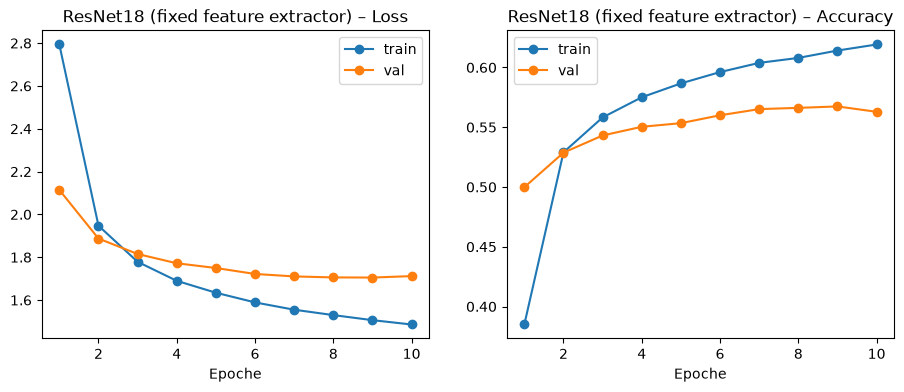

In [19]:
# 224 px, Batchgröße 32
run_frozen("ResNet18", epochs=10)   # Kopf 10 Epochen auf den ResNet18-Features trainieren

### 3.2 ResNet18 Fine-Tuning

[ 1] train loss 1.812 acc  54.8 % | val loss 1.396 acc  64.5 %
[ 2] train loss 1.137 acc  69.7 % | val loss 1.274 acc  68.3 %
Test-Accuracy: 72.68 %  |  Trainingszeit: 192.5 s


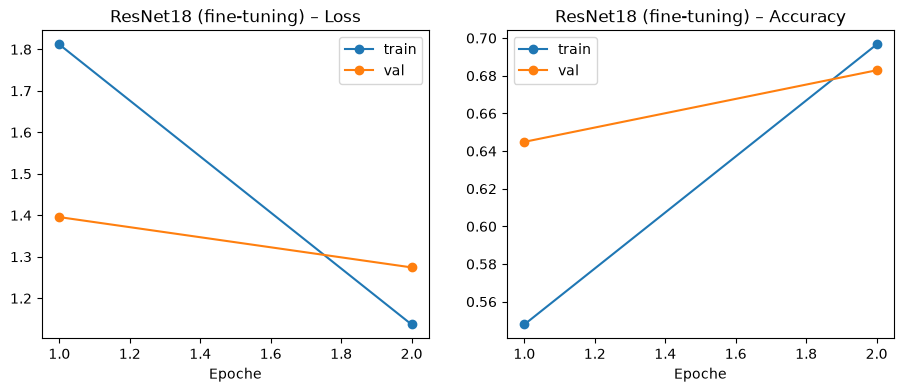

In [20]:
# Backbone lr 1e-4, Kopf lr 1e-3
run_finetune("ResNet18", epochs=2)   # ganzes ResNet18 2 Epochen nachtrainieren

### 3.3 EfficientNet_B5 als Fixed Feature Extractor

Features für train+val berechnet in 525.1 s, Feature-Dimension 2048
[ 1] train loss 2.113 acc  55.8 % | val loss 1.425 acc  65.6 %
[ 2] train loss 1.300 acc  68.0 % | val loss 1.216 acc  69.2 %
[ 3] train loss 1.142 acc  71.0 % | val loss 1.129 acc  70.9 %
[ 4] train loss 1.056 acc  72.8 % | val loss 1.076 acc  71.8 %
[ 5] train loss 1.000 acc  74.2 % | val loss 1.043 acc  72.8 %
[ 6] train loss 0.958 acc  75.0 % | val loss 1.018 acc  73.3 %
[ 7] train loss 0.924 acc  75.7 % | val loss 1.000 acc  73.6 %
[ 8] train loss 0.896 acc  76.5 % | val loss 0.982 acc  74.2 %
[ 9] train loss 0.873 acc  76.7 % | val loss 0.975 acc  74.3 %
[10] train loss 0.853 acc  77.4 % | val loss 0.963 acc  74.4 %
Test-Accuracy: 79.47 %  |  Trainingszeit: 530.5 s


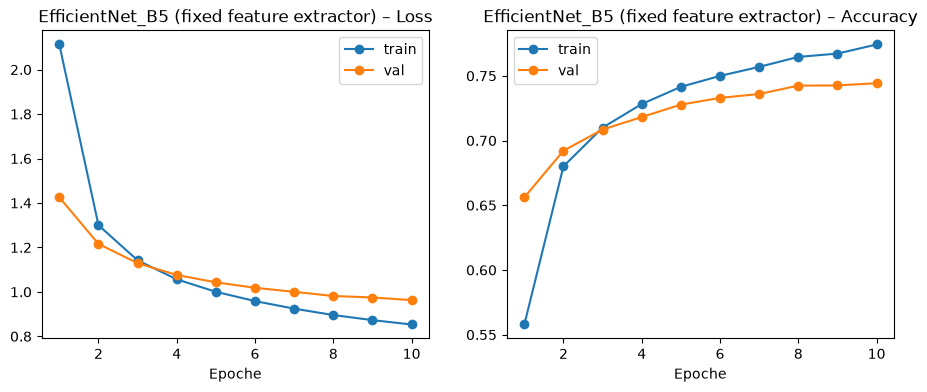

In [21]:
# 456 px, Batchgröße 16 wegen GPU-Speicher
run_frozen("EfficientNet_B5", epochs=10, batch_size=16)   # Kopf 10 Epochen auf den EfficientNet-Features trainieren

### 3.4 EfficientNet_B5 Fine-Tuning

[ 1] train loss 1.231 acc  68.7 % | val loss 0.703 acc  81.3 %
[ 2] train loss 0.605 acc  83.4 % | val loss 0.657 acc  83.3 %
Test-Accuracy: 87.49 %  |  Trainingszeit: 3375.9 s


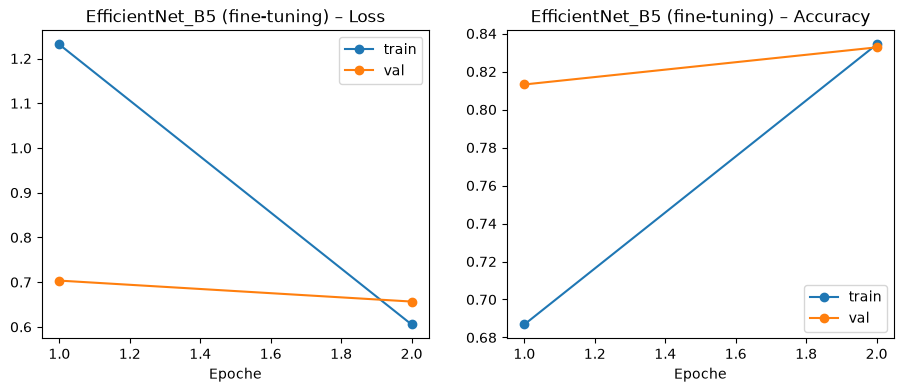

In [23]:
# ca. 28 min pro Epoche (Forward + Backward durch das ganze Netz bei 456 px)
run_finetune("EfficientNet_B5", epochs=2, batch_size=16)   # ganzes EfficientNet_B5 2 Epochen nachtrainieren

## 4. Vergleich aller Ansätze

Alle Werte stammen aus demselben Test-Split (25 250 Bilder), gemessen auf derselben GPU. Die Lernkurven aller Läufe lassen sich auch in TensorBoard vergleichen: `tensorboard --logdir runs/food101`.

Hinweis zur Spalte „Zeit pro Epoche“: Beim Feature Extractor ist das die Gesamtzeit geteilt durch 10. Fast die gesamte Zeit steckt aber im einmaligen Vorberechnen der Features, eine Kopf-Epoche selbst dauert unter einer Sekunde.

Modell,Strategie,Auflösung,Epochen,Trainierbare Parameter,Trainingszeit [s],Test-Accuracy [%],Zeit pro Epoche [s]
Custom CNN (BNNet),from scratch,64 px,10,"17,070,725",555.2,12.02,55.5
ResNet18,fixed feature extractor,224 px,10,"51,813",89.7,61.30,9.0
ResNet18,fine-tuning,224 px,2,"11,228,325",192.5,72.68,96.2
EfficientNet_B5,fixed feature extractor,456 px,10,"206,949",530.5,79.47,53.0
EfficientNet_B5,fine-tuning,456 px,2,"28,547,733",3375.9,87.49,1688.0


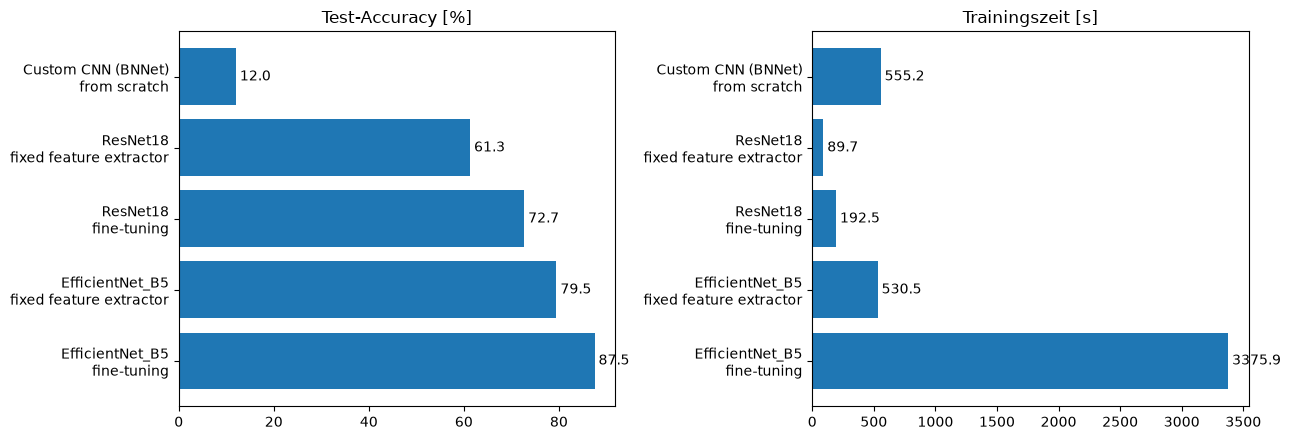

In [24]:
df = pd.DataFrame(results)   # Ergebnisliste -> Tabelle (eine Zeile pro Ansatz)
df["Zeit pro Epoche [s]"] = (df["Trainingszeit [s]"] / df["Epochen"]).round(1)   # zusätzliche Spalte berechnen
display(df.style.format({"Trainierbare Parameter": "{:,}", "Trainingszeit [s]": "{:.1f}",          # Tabelle formatiert anzeigen:
                         "Test-Accuracy [%]": "{:.2f}", "Zeit pro Epoche [s]": "{:.1f}"}).hide(axis="index"))   # Tausendertrennzeichen, Nachkommastellen, ohne Index

# Balkendiagramme: links Accuracy, rechts Trainingszeit, gleiche Reihenfolge der Ansätze
labels = [f"{m}\n{s}" for m, s in zip(df["Modell"], df["Strategie"])]   # Beschriftung: Modell + Strategie in zwei Zeilen
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))                       # zwei Diagramme nebeneinander
for ax, col in zip(axes, ("Test-Accuracy [%]", "Trainingszeit [s]")):  # je ein Diagramm pro Spalte
    ax.barh(labels, df[col])   # horizontale Balken
    ax.set(title=col)          # Spaltenname als Titel
    ax.invert_yaxis()   # erster Ansatz oben
    for i, v in enumerate(df[col]):            # für jeden Balken
        ax.text(v, i, f" {v:.1f}", va="center")   # Wert neben den Balken schreiben
plt.tight_layout()   # Abstände automatisch anpassen, damit sich nichts überlappt
plt.show()           # Abbildung anzeigen

## 5. Interpretation

| Modell | Strategie | Auflösung | Epochen | Trainierbare Parameter | Trainingszeit | Test-Accuracy |
|---|---|---:|---:|---:|---:|---:|
| Custom CNN | from scratch | 64 px | 10 | 17,07 M | 555 s | 12,0 % |
| ResNet18 | fixed feature extractor | 224 px | 10 | 0,05 M | 90 s | 61,3 % |
| ResNet18 | fine-tuning | 224 px | 2 | 11,23 M | 193 s | 72,7 % |
| EfficientNet_B5 | fixed feature extractor | 456 px | 10 | 0,21 M | 531 s | 79,5 % |
| EfficientNet_B5 | fine-tuning | 456 px | 2 | 28,55 M | 3376 s | **87,5 %** |

### Custom CNN (Baseline)
- 12,0 % liegt klar über dem Zufallsniveau (1 %), ist aber weit hinter allen vortrainierten Modellen.
- **Die ersten 4 Epochen passiert fast nichts:** Der Loss bleibt bei 4,616 ≈ ln(101), das Netz gibt also für alle Klassen fast dieselbe Wahrscheinlichkeit aus. Erst ab Epoche 5 lernt es. Eine mögliche Ursache ist die große `fc1`-Schicht mit Dropout, bei der SGD mit lr 0.01 eine Weile braucht, um aus dem Anfangszustand herauszufinden. Ein Learning-Rate-Warmup oder Adam könnte das verkürzen.
- **Unteranpassung:** Die Val-Accuracy steigt nach Epoche 10 noch steil an (6,6 → 9,7 → 10,8 %), mehr Epochen würden also helfen. Train- und Val-Accuracy liegen nah beieinander (Train sogar darunter, weil die Train-Accuracy mit aktivem Dropout und Augmentation während der Epoche gemessen wird). Von Overfitting ist das Netz weit entfernt.
- **Auflösung:** Bei 64×64 px gehen viele Details verloren, an denen man Gerichte unterscheidet (Textur, Beilagen).
- Das CNN hat mehr Parameter als ResNet18, schneidet aber viel schlechter ab. Entscheidend sind die vortrainierten Features, nicht die Parameterzahl.
- Eine Epoche dauert ca. 55 s. Begrenzt ist das nicht durch die GPU (das Netz ist winzig), sondern durch das Dekodieren der JPEGs im DataLoader.

### Fixed Feature Extractor
- Schon der eingefrorene ResNet18 erreicht mit nur 51 813 trainierbaren Parametern **61,3 %**, das Fünffache der Baseline, in einem Sechstel der Zeit.
- **Zeitaufteilung:** 85 s für das Vorberechnen der ResNet18-Features (525 s bei EfficientNet_B5), danach nur ca. 5 s für 10 Epochen Kopf-Training. Ohne das Vorberechnen würde jede Epoche einen kompletten Backbone-Durchlauf kosten, also grob 10× so lange.
- Leichtes Overfitting des linearen Kopfes: ResNet18 61,9 % train vs. 56,3 % val, EfficientNet_B5 77,4 % vs. 74,4 %. Die Val-Accuracy flacht nach ca. 8 Epochen ab.
- **EfficientNet_B5 als Feature Extractor (79,5 %) ist sogar besser als ResNet18 mit Fine-Tuning (72,7 %).** Die EfficientNet-Features sind deutlich stärker (ImageNet-Top-1 83 % vs. 70 %, höhere Auflösung, 2048- statt 512-dimensional). Außerdem enthält ImageNet selbst schon einige Essensklassen (z. B. pizza, cheeseburger, hotdog, carbonara, guacamole, burrito, ice cream), die Domänen liegen also nah beieinander.

### Fine-Tuning
- Gegenüber dem eingefrorenen Backbone: **+11,4 Prozentpunkte** bei ResNet18 (61,3 → 72,7 %) und **+8,0 Prozentpunkte** bei EfficientNet_B5 (79,5 → 87,5 %). Die Features passen sich an Food-101 an.
- Die differenzierten Lernraten sorgen für stabiles Training: Schon nach der ersten Epoche liegt die Val-Accuracy bei 64,5 % bzw. 81,3 %.
- **Noch nicht auskonvergiert:** Nach 2 Epochen liegen Train- und Val-Accuracy nah beieinander (ResNet18 69,7 / 68,3 %, EfficientNet_B5 83,4 / 83,3 %), und die Val-Accuracy steigt noch. Mehr Epochen würden wahrscheinlich noch einige Prozentpunkte bringen, bevor Overfitting einsetzt.
- **Kosten:** Fine-Tuning braucht einen vollständigen Forward- **und** Backward-Pass durch das ganze Netz, für jedes Bild in jeder Epoche. Bei EfficientNet_B5 dauert eine Epoche 28 min.

### ResNet18 vs. EfficientNet_B5
- EfficientNet_B5 ist bei beiden Strategien deutlich besser (+18 bzw. +15 Prozentpunkte).
- Es ist aber auch deutlich teurer: 456 px statt 224 px Eingabe, ca. 10,3 statt 1,8 GFLOPs pro Bild, 2,5× so viele Parameter. Fine-Tuning dauert **17,5× so lange** wie bei ResNet18 (3376 s vs. 193 s).
- **Aufwand vs. Ergebnis:**
  - Beste Accuracy: EfficientNet_B5 Fine-Tuning (87,5 %, 56 min)
  - Guter Kompromiss: EfficientNet_B5 als Feature Extractor (79,5 %, 9 min) oder ResNet18 Fine-Tuning (72,7 %, 3 min)
  - Schnell und solide: ResNet18 als Feature Extractor (61,3 %, 1,5 min)

### Test- vs. Validierungs-Accuracy
Bei allen Transfer-Modellen liegt die Test-Accuracy **4–5 Prozentpunkte über** der Val-Accuracy (z. B. 87,5 vs. 83,3 %). Das ist kein Fehler: Die Validierungsbilder stammen aus dem train-Split, der absichtlich Label-Rauschen enthält. Ein Teil der „Fehler“ auf val sind also falsch beschriftete Bilder. Der test-Split wurde dagegen von Hand bereinigt.

### Einschränkungen des Vergleichs
- **Gleich:** Split, Metrik, Hardware, Trainingsschleife, Zeitmessung
- **Unterschiedlich:**
  - Epochen: 10 / 10 / 2
  - Auflösung: von den Gewichten vorgegeben
  - Batchgröße: 16 bei EfficientNet_B5
  - Augmentation: beim Feature Extractor kein Spiegeln
- **Ein Seed pro Konfiguration.** Bei 25 250 Testbildern liegt der Standardfehler der Accuracy aber nur bei ca. √(p(1−p)/n) ≈ 0,3 Prozentpunkte. Die Abstände zwischen den Ansätzen (≥ 6 Prozentpunkte) sind also eindeutig.

### Fazit
Transfer Learning ist dem Training von Grund auf klar überlegen, sowohl bei der Accuracy als auch bei der Zeit bis zu einem brauchbaren Ergebnis. Fine-Tuning schlägt den Fixed Feature Extractor, kostet aber deutlich mehr Rechenzeit. Die beste Accuracy liefert EfficientNet_B5 mit Fine-Tuning. Das beste Verhältnis aus Aufwand und Ergebnis liefern ResNet18 mit Fine-Tuning und EfficientNet_B5 als Feature Extractor.

## 6. Mögliche Fragen und Antworten

**Warum ein eigener Validierungs-Split und nicht einfach der Test-Split?**
Wenn man während des Trainings auf den Test-Split schaut (z. B. um die Epochenzahl oder Lernrate zu wählen), passt man sich indirekt an die Testdaten an, und die Test-Accuracy ist zu optimistisch. Der Test-Split wird deshalb pro Modell nur einmal am Ende ausgewertet.

**Warum Top-1-Accuracy?**
Die Klassen sind balanciert (250 Testbilder pro Klasse), daher gewichtet die Accuracy jede Klasse gleich. Bei unbalancierten Daten müsste man z. B. Balanced Accuracy oder Macro-F1 nehmen.

**Was macht BatchNorm im Training anders als bei der Auswertung?**
Im Training (`net.train()`) wird mit Mittelwert/Varianz des aktuellen Batches normalisiert, gleichzeitig werden Running-Statistiken aktualisiert. Bei `net.eval()` werden diese gespeicherten Statistiken verwendet, die Vorhersage für ein Bild hängt dann nicht mehr vom Rest des Batches ab. Deshalb ist `net.eval()` in `evaluate()` wichtig.

**Was bewirkt `requires_grad=False`?**
Für diese Parameter werden keine Gradienten berechnet und sie werden nicht aktualisiert. Zusätzlich übergibt man dem Optimierer nur die Kopf-Parameter.

**Ist das Vorberechnen der Features nicht „geschummelt“?**
Nein. Ein eingefrorenes Backbone im `eval`-Modus ist eine feste Funktion, es liefert für dasselbe Bild immer denselben Vektor. Ob man das jede Epoche neu berechnet oder einmal speichert, ergibt dasselbe Modell. Der einzige Unterschied ist die fehlende Spiegel-Augmentation. Die Zeit fürs Vorberechnen ist in der Trainingszeit enthalten.

**Warum unterschiedliche Lernraten beim Fine-Tuning?**
Der Kopf ist zufällig initialisiert und braucht eine größere Lernrate. Das Backbone ist schon gut und soll nur leicht angepasst werden. Mit 1e-3 für alles würden die vortrainierten Gewichte am Anfang durch die großen Gradienten des zufälligen Kopfes stark verändert („catastrophic forgetting“).

**Warum `weights.transforms()`?**
Die Netze wurden mit einer bestimmten Auflösung und ImageNet-Normalisierung trainiert. Bekommen sie anders vorverarbeitete Bilder, passen die gelernten Features schlechter. Mit den mitgelieferten Transforms ist das garantiert konsistent.

**Was ist bf16-Autocast und warum?**
Rechnungen laufen automatisch in 16-Bit-Gleitkomma (bfloat16), wo das sicher ist, z. B. bei Faltungen und Matrixmultiplikationen. Das halbiert den Speicher für Aktivierungen und ist auf Tensor-Cores schneller. bfloat16 hat denselben Exponentenbereich wie float32, deshalb braucht man (anders als bei float16) keinen GradScaler. Die Loss-Berechnung erfolgt in float32 (`.float()`).

**Warum `torch.cuda.synchronize()` vor dem Stoppen der Zeit?**
CUDA-Aufrufe laufen asynchron, Python wartet nicht, bis die GPU fertig ist. Ohne Synchronisierung könnte die Zeit gemessen werden, während die GPU noch rechnet.

**Warum dauert EfficientNet_B5 so viel länger als ResNet18?**
Die Eingabe ist ca. 4× so groß (456² vs. 224² Pixel), es braucht ca. 5,7× so viele FLOPs pro Bild (10,3 vs. 1,8 GFLOPs), und die Depthwise-Faltungen in EfficientNet nutzen die GPU schlechter aus als die normalen Faltungen von ResNet. Dazu kommt die halbe Batchgröße.

**Warum ist die Test-Accuracy höher als die Val-Accuracy?**
Validierung kommt aus dem train-Split mit absichtlichem Label-Rauschen, der test-Split wurde manuell bereinigt (siehe Interpretation).

**Warum hat das CNN mehr Parameter als ResNet18, ist aber viel schlechter?**
Fast alle CNN-Parameter stecken in einer einzigen FC-Schicht (`fc1`), nicht in Faltungen. Vor allem aber wurde ResNet18 auf 1,2 M Bildern vortrainiert, das CNN startet bei null.

**Was würde man verbessern, wenn mehr Zeit wäre?**
- Mehr Epochen beim Fine-Tuning und beim CNN
- Learning-Rate-Scheduler (z. B. Cosine) und Early Stopping auf der Val-Accuracy
- Stärkere Augmentation (`RandomResizedCrop`, Farb-Jitter)
- Label Smoothing gegen das Label-Rauschen
- Mehrere Seeds, um Streuung anzugeben
- Partielles Fine-Tuning (nur die letzten Blöcke auftauen) als Mittelweg zwischen den beiden Strategien

Batch Normalization normalisiert die Aktivierungen einer Schicht pro Kanal über den aktuellen Mini-Batch. Danach skaliert und verschiebt sie das Ergebnis wieder mit lernbaren Parametern.

Was nn.BatchNorm2d(32) konkret rechnet
Die Eingabe hat die Form (Batch, 32, H, W), also 32 Feature-Maps, z. B. aus einer Conv2d(..., 32, ...). Für jeden der 32 Kanäle passiert Folgendes:

Mittelwert μ und Varianz σ² über alle Bilder im Batch und alle Pixel (B × H × W Werte) berechnen.
Normalisieren: x̂ = (x − μ) / √(σ² + ε), danach hat der Kanal ungefähr Mittelwert 0 und Varianz 1.
Skalieren und verschieben: y = γ · x̂ + β. γ und β werden pro Kanal gelernt, das sind 2 × 32 Parameter.
Mit γ und β kann das Netz die Normalisierung bei Bedarf auch wieder „rückgängig“ machen. BN schränkt das Modell also nicht ein.

Training vs. Evaluation
net.train(): Es werden μ und σ² des aktuellen Batches benutzt. Nebenbei führt die Schicht einen gleitenden Mittelwert (running_mean, running_var) mit.
net.eval(): Es werden die gespeicherten Running-Statistiken benutzt. Dadurch hängt die Vorhersage nicht davon ab, welche anderen Bilder zufällig im Batch sind.
Deshalb ist net.eval() in evaluate() wichtig. Ohne diesen Aufruf wären Val- und Test-Ergebnisse verfälscht.

Warum man das macht
Stabileres, schnelleres Training: Die Eingaben jeder Schicht bleiben in einem ähnlichen Wertebereich. Deshalb verträgt das Netz höhere Lernraten, z. B. lr=0.01 mit SGD + Momentum.
Bessere Gradienten: Aktivierungen geraten seltener in Bereiche, in denen Gradienten verschwinden oder explodieren.
Leichte Regularisierung: Die Batch-Statistiken schwanken etwas, das wirkt ähnlich wie Rauschen.
Weniger empfindlich gegenüber der Initialisierung.
Typische Platzierung
Conv → BatchNorm → ReLU. Die Conv-Schicht davor braucht dann oft kein bias, also bias=False, weil β diese Rolle übernimmt.

Daher kommt auch der Name „BNNet“: Es ist das Custom-CNN mit BatchNorm-Schichten, das ohne sie bei 10 Epochen from scratch auf Food-101 deutlich schlechter und instabiler trainieren würde.